In [2]:
import pandas as pd
import re
import nltk
import os
import kagglehub
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer


nltk.download('stopwords')
nltk.download('wordnet')


path = kagglehub.dataset_download("PromptCloudHQ/amazon-reviews-unlocked-mobile-phones")
csv_files = [f for f in os.listdir(path) if f.endswith('.csv')]
file_path = os.path.join(path, csv_files[0])


df = pd.read_csv(file_path)


df = df.dropna(subset=['Reviews', 'Rating'])

df = df.sample(20000, random_state=42)


df['Sentiment'] = df['Rating'].apply(lambda x: 'positive' if x > 3 else ('negative' if x < 3 else 'neutral'))


lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = str(text)

    text = text.lower()

    text = re.sub(r'[^a-z\s]', '', text)

    words = text.split()

    words = [w for w in words if w not in stop_words]

    words = [lemmatizer.lemmatize(w) for w in words]
    return ' '.join(words)


df['Clean_Text'] = df['Reviews'].apply(preprocess_text)
print("Preprocessing complete. Sample data:")
display(df[['Clean_Text', 'Sentiment']].head())

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


100%|██████████| 32.6M/32.6M [00:02<00:00, 12.5MB/s]

Extracting files...


Preprocessing complete. Sample data:


,Clean_Text,Sentiment
262853,needed texting phone require data plan also ne...,negative
70999,excellent,positive
324745,recommend excellent team many differentiating ...,positive
114637,updated review purchased phone november worked...,positive
221325,battery fail,neutral


In [3]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(df['Clean_Text'], df['Sentiment'], test_size=0.2, random_state=42)

print(f"Training data size: {X_train.shape[0]}")
print(f"Testing data size: {X_test.shape[0]}")

Training data size: 16000
Testing data size: 4000


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=5000)
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print("TF-IDF Vectorization complete.")

TF-IDF Vectorization complete.


In [5]:
from sklearn.naive_bayes import MultinomialNB

nb_classifier = MultinomialNB()
nb_classifier.fit(X_train_tfidf, y_train)

print("Naive Bayes Classifier successfully trained.")

Naive Bayes Classifier successfully trained.


In [6]:
from sklearn.metrics import accuracy_score, classification_report

y_pred = nb_classifier.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.81

Classification Report:
              precision    recall  f1-score   support

    negative       0.83      0.62      0.71       945
     neutral       0.00      0.00      0.00       341
    positive       0.81      0.98      0.89      2714

    accuracy                           0.81      4000
   macro avg       0.55      0.53      0.53      4000
weighted avg       0.74      0.81      0.77      4000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


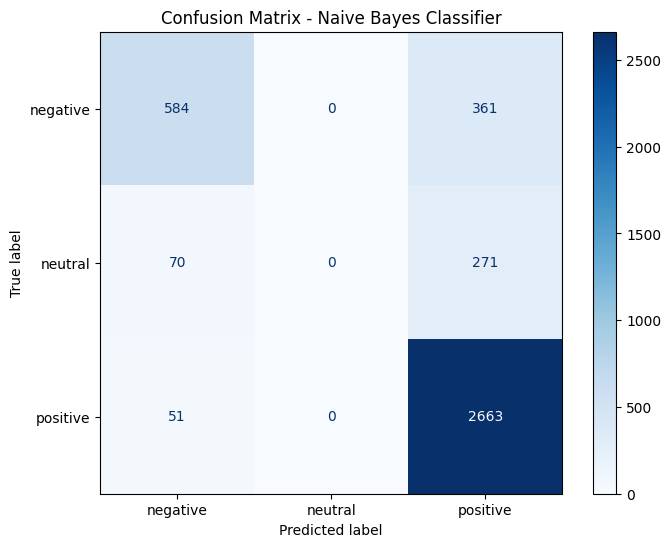

In [7]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred, labels=nb_classifier.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=nb_classifier.classes_)

fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(cmap='Blues', ax=ax)
plt.title('Confusion Matrix - Naive Bayes Classifier')
plt.show()